# Q2 - Copy Mutate with Addition and Deletion


In Q1 all recipes stayed the same size because we were only replacing ingredients. Here we change the algorithm so that a copied recipe can also get an ingredient added or deleted, and then compare recipe size and frequency rank over 5 runs with the real cuisine.

In [25]:
import random
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

DATA_PATH   = "Q1b_NER.csv"
NR0         = 200
N_INSTANCES = 5
SEEDS       = [11, 22, 33, 44, 55]
MAX_TRIES   = 10_000

plt.rcParams.update({"figure.dpi": 110, "font.size": 11})

In [26]:
df = pd.read_csv(DATA_PATH)
df["Ingredient_Name"] = df["Ingredient_Name"].astype(str).str.strip().str.lower()
df = df[~df["Ingredient_Name"].isin(["", "nan"])]

real_recipes = [frozenset(g) for _, g in df.groupby("Recipe_ID")["Ingredient_Name"]]
real_recipes = [r for r in real_recipes if len(r) > 0]

N_R           = len(real_recipes)
nature_basket = sorted(set().union(*real_recipes))
N_I           = len(nature_basket)
real_sizes    = np.array([len(r) for r in real_recipes])
S             = int(round(real_sizes.mean()))
MAX_SIZE      = int(real_sizes.max())

N_EPOCHS          = int(round(N_R / NR0))
RECIPES_PER_EPOCH = int(round(N_R / N_EPOCHS))
PHI = N_I / N_R
KB0 = max(S + 1, int(round(PHI * NR0)))

print(f"Recipes (N_R)              : {N_R}")
print(f"Nature Basket size (N_I)   : {N_I}")
print(f"Recipe size s (mean, round): {S}   (mean={real_sizes.mean():.2f}, std={real_sizes.std():.2f})")
print(f"Epochs = round({N_R}/{NR0}) = round({N_R/NR0:.2f}) = {N_EPOCHS}")
print(f"Recipes per epoch = round({N_R}/{N_EPOCHS}) = round({N_R/N_EPOCHS:.2f}) = {RECIPES_PER_EPOCH}")
print(f"Primordial recipes NR(t=0) : {NR0}")
print(f"Initial Kitchen Basket     : {KB0}   (KB/NB ratio = {KB0/N_I:.4f})")

Recipes (N_R)              : 9988
Nature Basket size (N_I)   : 12641
Recipe size s (mean, round): 10   (mean=10.00, std=4.20)
Epochs = round(9988/200) = round(49.94) = 50
Recipes per epoch = round(9988/50) = round(199.76) = 200
Primordial recipes NR(t=0) : 200
Initial Kitchen Basket     : 253   (KB/NB ratio = 0.0200)


In [27]:
def size_distribution(recipes, max_size):
    """P(size): fraction of recipes having each size 0..max_size."""
    sizes = np.array([len(r) for r in recipes])
    counts = np.bincount(sizes, minlength=max_size + 1)[: max_size + 1]
    return counts / counts.sum(), sizes

def frequency_rank(recipes):
    """Normalised frequency f(r) = (#recipes containing rank-r ingredient) / (#recipes), sorted by rank."""
    c = Counter(ing for r in recipes for ing in r)
    return np.array(sorted(c.values(), reverse=True), dtype=float) / len(recipes)

def stack_ragged(arrays):
    """Pad 1-D arrays of different lengths with NaN so mean/std can be taken across instances."""
    L = max(len(a) for a in arrays)
    out = np.full((len(arrays), L), np.nan)
    for i, a in enumerate(arrays):
        out[i, : len(a)] = a
    return out

def label_log_axes(ax):
    """Label log-scale ticks at 1, 2 and 5 of every decade with plain numbers."""
    fmt = mticker.FuncFormatter(lambda v, _: f"{v:g}")
    for axis in (ax.xaxis, ax.yaxis):
        axis.set_major_locator(mticker.LogLocator(base=10, numticks=15))
        axis.set_minor_locator(mticker.LogLocator(base=10, subs=(2, 5), numticks=15))
        axis.set_major_formatter(fmt)
        axis.set_minor_formatter(fmt)
    ax.tick_params(axis="both", which="minor", labelsize=8)

def plot_size_distribution(results, title, fname):
    """Recipe-size distribution across instances (mean ± std bars), with overall mean and ±1 std marked."""
    max_size = max(MAX_SIZE, max(len(r) for res in results for r in res))
    P = np.array([size_distribution(res, max_size)[0] for res in results])
    all_sizes = np.concatenate([size_distribution(res, max_size)[1] for res in results])
    mu, sd = all_sizes.mean(), all_sizes.std()
    P_real, _ = size_distribution(real_recipes, max_size)
    x = np.arange(max_size + 1)

    fig, ax = plt.subplots(figsize=(10, 5.5))
    ax.bar(x, P.mean(0), yerr=P.std(0), capsize=3, color="tab:blue", alpha=0.75,
           label=f"Model (mean ± std over {len(results)} instances)")
    ax.plot(x, P_real, "o--", color="tab:red", ms=4, label="Real cuisine")
    ax.axvline(mu, color="k", lw=2, label=f"Model mean = {mu:.2f}")
    ax.axvspan(mu - sd, mu + sd, color="grey", alpha=0.2, label=f"Model mean ± std ({sd:.2f})")
    ax.set_xlabel("Recipe size, s (number of ingredients)")
    ax.set_ylabel("P(s)  (fraction of recipes)")
    ax.set_title(title)
    ax.set_xticks(x[:: 2 if max_size > 20 else 1])
    ax.set_xlim(0.5, max_size + 0.5)
    ax.yaxis.set_major_formatter(mticker.FormatStrFormatter("%.2f"))
    ax.legend(); ax.grid(alpha=0.3)
    fig.tight_layout(); fig.savefig(fname, dpi=300); plt.show()
    print(f"Saved {fname} | model size mean = {mu:.2f}, std = {sd:.2f} | "
          f"real mean = {real_sizes.mean():.2f}, std = {real_sizes.std():.2f}")

def plot_frequency_rank(results, title, fname):
    """Normalised frequency-rank distribution (log-log), mean ± std across instances vs real cuisine."""
    F = stack_ragged([frequency_rank(res) for res in results])
    mean, std = np.nanmean(F, 0), np.nanstd(F, 0)
    ranks = np.arange(1, F.shape[1] + 1)
    f_real = frequency_rank(real_recipes)

    fig, ax = plt.subplots(figsize=(9, 6))
    for i, row in enumerate(F):
        ax.plot(ranks, row, lw=0.6, alpha=0.4, label="Individual instances" if i == 0 else None)
    ax.plot(ranks, mean, color="tab:blue", lw=2, label=f"Model mean ({len(results)} instances)")
    ax.fill_between(ranks, np.clip(mean - std, 1e-6, None), mean + std,
                    color="tab:blue", alpha=0.25, label="Model mean ± std")
    ax.plot(np.arange(1, len(f_real) + 1), f_real, color="tab:red", lw=2, ls="--", label="Real cuisine")
    ax.set_xscale("log"); ax.set_yscale("log"); label_log_axes(ax)
    ax.set_xlabel("Rank, r (log scale)")
    ax.set_ylabel("Normalised frequency, f(r) = n(r) / N_R (log scale)")
    ax.set_title(title)
    ax.legend(); ax.grid(which="both", alpha=0.3)
    fig.tight_layout(); fig.savefig(fname, dpi=300); plt.show()
    print(f"Saved {fname}")

def summarise(results, label):
    """Key numbers of a set of runs vs the real cuisine (used in the observations)."""
    sizes = np.concatenate([[len(r) for r in res] for res in results])
    f1    = [frequency_rank(res)[0] for res in results]
    used  = [len(set().union(*res)) for res in results]
    f_real = frequency_rank(real_recipes)
    print(f"{label}")
    print(f"  recipe size        : mean = {sizes.mean():.2f}, std = {sizes.std():.2f}   "
          f"(real: {real_sizes.mean():.2f}, {real_sizes.std():.2f})")
    print(f"  f(1) top ingredient: {np.mean(f1):.3f} ± {np.std(f1):.3f}   (real: {f_real[0]:.3f})")
    print(f"  ingredients used   : {np.mean(used):.0f} ± {np.std(used):.0f}   (real: {len(f_real)})")

## Modified algorithm

Everything is same as Q1 except what happens after a recipe is copied. Now with probability 1/3 it is modified like in Q1, with 1/3 a random KB ingredient that is not already in it gets added, and with 1/3 a random ingredient is deleted. We kept all three equal so adding and deleting happen equally often and the mean size stays near 10 instead of growing or shrinking.

We also set a minimum size of 2 because a recipe with less then 2 ingredients isnt really a combination, and a maximum of 33 since thats the biggest recipe in the real data. If an add or delete is not allowed because of these limits that copy is skipped and another recipe is picked. op_counts counts how many of each type got accepted.

In [28]:
P_MODIFY, P_ADD, P_DELETE = 1/3, 1/3, 1/3
MIN_SIZE = 2
op_counts = Counter()

def grow_kitchen(kb_list, kb_set, target_size, nb_pool):
    """Move new ingredients from the (shuffled) Nature Basket into the Kitchen Basket."""
    while len(kb_list) < target_size and nb_pool:
        ing = nb_pool.pop()
        kb_list.append(ing); kb_set.add(ing)

def init_primordial(kb_list, rng):
    """Primordial cuisine: NR0 unique recipes, each with S random ingredients from KB."""
    cuisine_list, cuisine_set = [], set()
    while len(cuisine_list) < NR0:
        r = frozenset(rng.sample(kb_list, S))
        if r not in cuisine_set:
            cuisine_list.append(r); cuisine_set.add(r)
    return cuisine_list, cuisine_set

def modify(rec, kb_list, rng):
    """MODIFICATION: replace a random recipe ingredient with a different random KB ingredient (as in Q1)."""
    for _ in range(MAX_TRIES):
        i = rng.randrange(len(rec))
        new = kb_list[rng.randrange(len(kb_list))]
        if new != rec[i] and new not in rec:
            rec[i] = new
            return rec
    return None

def add(rec, kb_list, rng):
    """ADDITION: append a random KB ingredient not already in the recipe."""
    if len(rec) >= MAX_SIZE:
        return None
    for _ in range(MAX_TRIES):
        new = kb_list[rng.randrange(len(kb_list))]
        if new not in rec:
            rec.append(new)
            return rec
    return None

def delete(rec, rng):
    """DELETION: remove a random ingredient from the recipe."""
    if len(rec) <= MIN_SIZE:
        return None
    rec.pop(rng.randrange(len(rec)))
    return rec

def mutate(recipe, kb_list, rng):
    """Choose one mutation type (modify / add / delete) and apply it to a copy of the recipe."""
    op = rng.choices(["modify", "add", "delete"], weights=[P_MODIFY, P_ADD, P_DELETE])[0]
    rec = sorted(recipe)
    if op == "modify":
        out = modify(rec, kb_list, rng)
    elif op == "add":
        out = add(rec, kb_list, rng)
    else:
        out = delete(rec, rng)
    return (frozenset(out), op) if out is not None else (None, op)

def evolve_cuisine(seed):
    """Run one instance of cuisine evolution and return the final cuisine."""
    rng = random.Random(seed)
    nb_pool = nature_basket[:]; rng.shuffle(nb_pool)
    kb_list, kb_set = [], set()
    grow_kitchen(kb_list, kb_set, KB0, nb_pool)
    cuisine_list, cuisine_set = init_primordial(kb_list, rng)

    for epoch in range(1, N_EPOCHS):
        target = N_R if epoch == N_EPOCHS - 1 else min(N_R, NR0 + epoch * RECIPES_PER_EPOCH)
        grow_kitchen(kb_list, kb_set, int(round(PHI * target)), nb_pool)
        while len(cuisine_list) < target:
            parent = cuisine_list[rng.randrange(len(cuisine_list))]
            child, op = mutate(parent, kb_list, rng)
            if child is not None and child not in cuisine_set:
                cuisine_list.append(child); cuisine_set.add(child)
                op_counts[op] += 1
    return cuisine_list

## Running 5 instances

Same 5 seeds as Q1, for each run we print mean and std of recipe size and the number of ingredients used.

In [29]:
results = []
for k, seed in enumerate(SEEDS[:N_INSTANCES], 1):
    cuisine = evolve_cuisine(seed)
    results.append(cuisine)
    sz = np.array([len(r) for r in cuisine])
    print(f"Instance {k} (seed={seed}): {len(cuisine)} recipes | size mean={sz.mean():.2f}, "
          f"std={sz.std():.2f} | {len(set().union(*cuisine))} distinct ingredients used")
print("Accepted mutations by type (all instances):", dict(op_counts))

Instance 1 (seed=11): 9988 recipes | size mean=10.11, std=1.56 | 4448 distinct ingredients used
Instance 2 (seed=22): 9988 recipes | size mean=10.15, std=1.64 | 4514 distinct ingredients used
Instance 3 (seed=33): 9988 recipes | size mean=10.06, std=1.64 | 4462 distinct ingredients used
Instance 4 (seed=44): 9988 recipes | size mean=10.14, std=1.68 | 4467 distinct ingredients used
Instance 5 (seed=55): 9988 recipes | size mean=10.08, std=1.60 | 4497 distinct ingredients used
Accepted mutations by type (all instances): {'add': 16762, 'delete': 15592, 'modify': 16586}


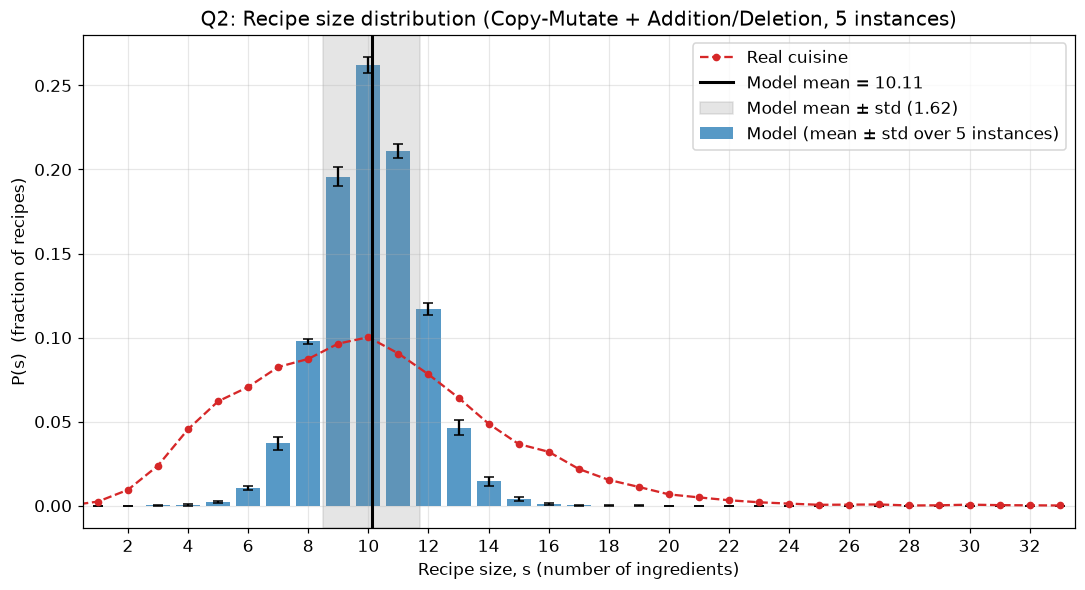

Saved Q2_Recipe_Size_Distribution.png | model size mean = 10.11, std = 1.62 | real mean = 10.00, std = 4.20


In [30]:
plot_size_distribution(results, "Q2: Recipe size distribution (Copy-Mutate + Addition/Deletion, 5 instances)",
                       "Q2_Recipe_Size_Distribution.png")

## Recipe size observations

Mean size is 10.11 and std is 1.62 so now recipes have different sizes unlike Q1, the shape is like a bell around 10 going roughly from 5 to 15. But the real std is 4.20 and the real data has a longer tail on the right with big recipes upto 33, so the model is still too narrow. This is because every new recipe is only a few copy steps away from its starting recipe so it only gets a few +1 or -1 changes. The accepted mutations were almost equal (add 16762, delete 15592, modify 16586 over 5 runs) so there is nothing pushing recipes to be bigger or smaller.

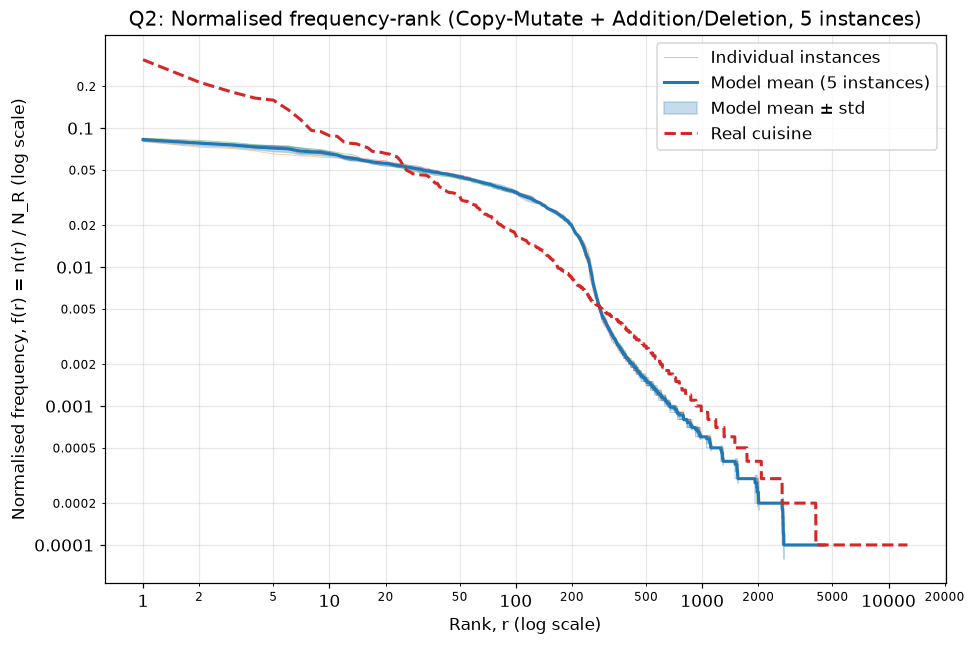

Saved Q2_Frequency_Rank_Distribution.png


In [31]:
plot_frequency_rank(results, "Q2: Normalised frequency-rank (Copy-Mutate + Addition/Deletion, 5 instances)",
                    "Q2_Frequency_Rank_Distribution.png")

## Frequency rank observations

The shape is nearly the same as Q1 with a flat top and a drop near rank 250. f(1) is 0.083 which is still far from the real 0.311. The model uses about 4478 ingredients which is less then Q1 (5646), because only modification and addition bring in new ingredients while deletion takes them out. So addition and deletion help with recipe size but dont really change the popularity pattern.

In [32]:
summarise(results, "Q2")

Q2
  recipe size        : mean = 10.11, std = 1.62   (real: 10.00, 4.20)
  f(1) top ingredient: 0.083 ± 0.002   (real: 0.311)
  ingredients used   : 4478 ± 24   (real: 12641)


## Conclusion

Adding addition and deletion fixes the main issue of Q1 since recipes now have different sizes and the mean stays around 10, but the spread is still much smaller then the real cuisine. Frequency rank is almost unchanged because every kitchen ingredient still has the same chance to be picked, so in Q3 we give popular ingredients an advantage.